# Exercise Sheet for Interpolation and Approximation
----------------------------------------------------------

In [236]:
#load some python packages you will need
import numpy as np                 #this helps compute things
import matplotlib.pyplot as plt    #this helps plot things
import sympy as sp
import math

## Question 1
### a) Compute via interpolation and plot the Lagrange polynomial p(x) to $f(x) = cos(-2\pi x) + 0.4x^2$ over
### $(x_i,y_i) = [(7.2,21.04),(7.4,21.12),(7.6,22.39),(7.8,24.77]$ 


### b) Estimate the maximum absolute error bound for this Lagrange polynomial approximation over $\xi \in [x_0,x_n]$

In [237]:
x = np.arange(7,8,0.001)   #dummy range for function
y = np.cos(-2*np.pi*x) +0.4*x**2  #function f(x)


In [238]:
xi = np.array((7.2,7.4,7.6,7.8))   # points for interpolation
yi = y[np.digitize(xi,x)]


In [239]:
x_1 = sp.Symbol('x')
p = 0

for i in range(len(xi)):
    L = 1

    for j in range(len(xi)):
        if i != j:
            L = L * (x_1 - xi[j]) / (xi[i] - xi[j])
    p = p + yi[i] * L



p_x_simplified = (sp.simplify(p))
print("Lagrange-Polynomial:", p_x_simplified)

p_func = sp.lambdify(x_1, p_x_simplified, 'numpy')

Lagrange-Polynomial: -3.59250407200307e-11*x**3 + 14.3754248601872*x**2 - 209.631372896692*x + 785.168877112243


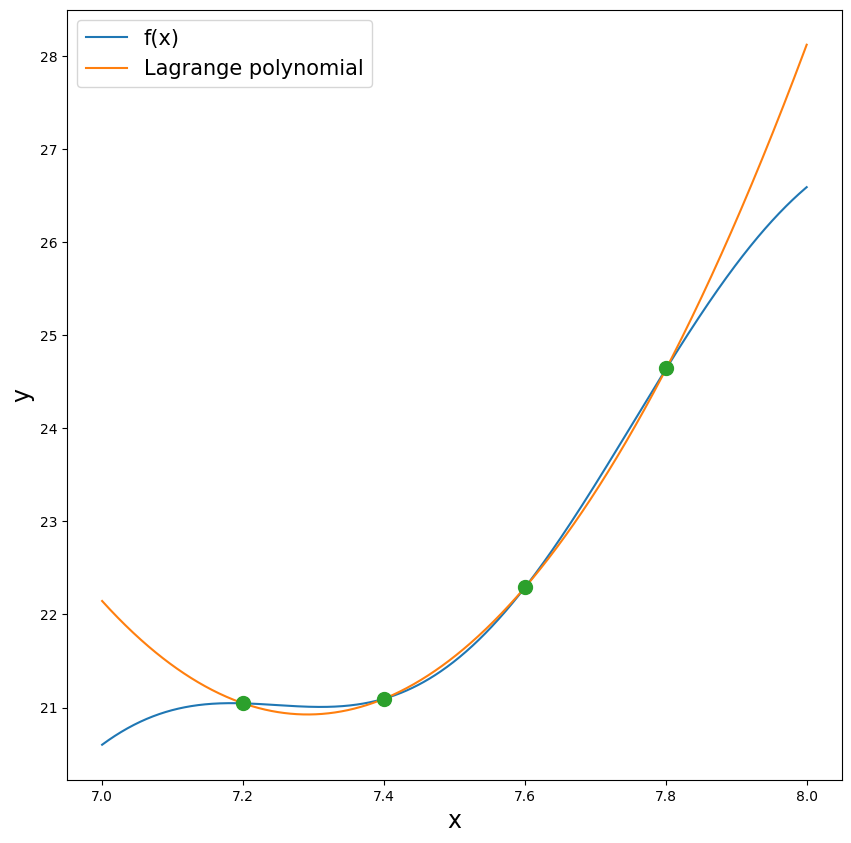

In [240]:
plt.figure(figsize=(10,10))
plt.plot(x,y,label='f(x)') 
plt.plot(x,p_func(x),label='Lagrange polynomial') 
plt.plot(xi,yi,'o',markersize=10)
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)
plt.legend(loc='best',fontsize=15)

In [241]:
#b
f = sp.cos(-2*sp.pi*x_1) + 0.4*x_1**2
d4f_dx4 = sp.diff(f, x_1, 4)
max_d4f_dx4 = sp.Max(d4f_dx4)

product = 1

for i in range(len(xi)):
    product *= (x_1 - xi[i])

product_derivative = sp.diff(product, x_1)

critical_points = sp.solve(product_derivative, x_1)

candidates = [xi[0], xi[-1]]

for point in critical_points:
    if point.is_real:
        point_value = float(point)

        if xi[0] <= point_value <= xi[-1]:
            candidates.append(point_value)

product_values = [
    abs(float(product.subs(x_1, point)))
    for point in candidates
]

max_product = max(product_values)

print("f''''(x) =", d4f_dx4)
print("Critical points:", critical_points)
print("Maximum product =", max_product)


f''''(x) = 16*pi**4*cos(2*pi*x)
Critical points: [7.27639320225002, 7.50000000000000, 7.72360679774998]
Maximum product = 0.0015999999999999986


----------------------------------------------------------

## Question 2
### Assume linear interpolation with step size $\textbf{d}$ is used to approximate $y(x) = \pi x^7$
### What step size for linear interpolation do you need to have for an absolute error $E_{max} < 10^{-6}$?. You can assume  $x \in [0,2]$.

In [242]:
x = sp.Symbol('x')
y = sp.pi * x**7

dy_dx = sp.diff(y, x)
d2y_dx2 = sp.diff(dy_dx, x)

max_d2y_dx2 = float(d2y_dx2.subs(x, 2)) #float um danach eine ganze zahl zu erhalten, da sonst ein sympy Objekt zurückgegeben wird

E_max = 10**-6
d = sp.sqrt((8 * E_max) / max_d2y_dx2)

print("f'(x)=", dy_dx)
print("f''(x) =", d2y_dx2)
print("f''(x)_max bei x=2:", max_d2y_dx2)
print("Maximum step size =", d)


f'(x)= 7*pi*x**6
f''(x) = 42*pi*x**5
f''(x)_max bei x=2: 4222.300526424682
Maximum step size = 4.35281713775682e-5


----------------------------------------------------------

## Question 3
### When using Taylor polynomials to approximate $y = cos(-3 \pi x) + 3x$ over the range $x = [-0.25,0.25]$, about $x= 0$;  to what order $j$ would you need to compute the interpolating polynomial in order to keep the maximum absolute error smaller than $E_{j}(x) < 10^{-6}$?

In [243]:
xs = sp.Symbol('x')
f_taylor = sp.cos(-3 * sp.pi * xs) + 3 * xs

E_limit = 1e-6
a = 0
distance = 0.25

j = 0

while True:
    derivative = sp.diff(f_taylor, xs, j+1)

    max_deriv_value = float((3 * sp.pi) ** (j + 1)) #Kettenregel diffgleichung: f'(g(x)) = f'(g(x)) * g'(x) => g'(x) = 3, daher 3^j+1


    error = max_deriv_value / math.factorial(j+1) * distance**(j+1)

    if error < E_limit:
        break

    j += 1

print("Required Taylor order:", j)
print("Maximum error bound:", error)


Required Taylor order: 14
Maximum error bound: 2.9286497132391215e-07


Text(0, 0.5, 'y')

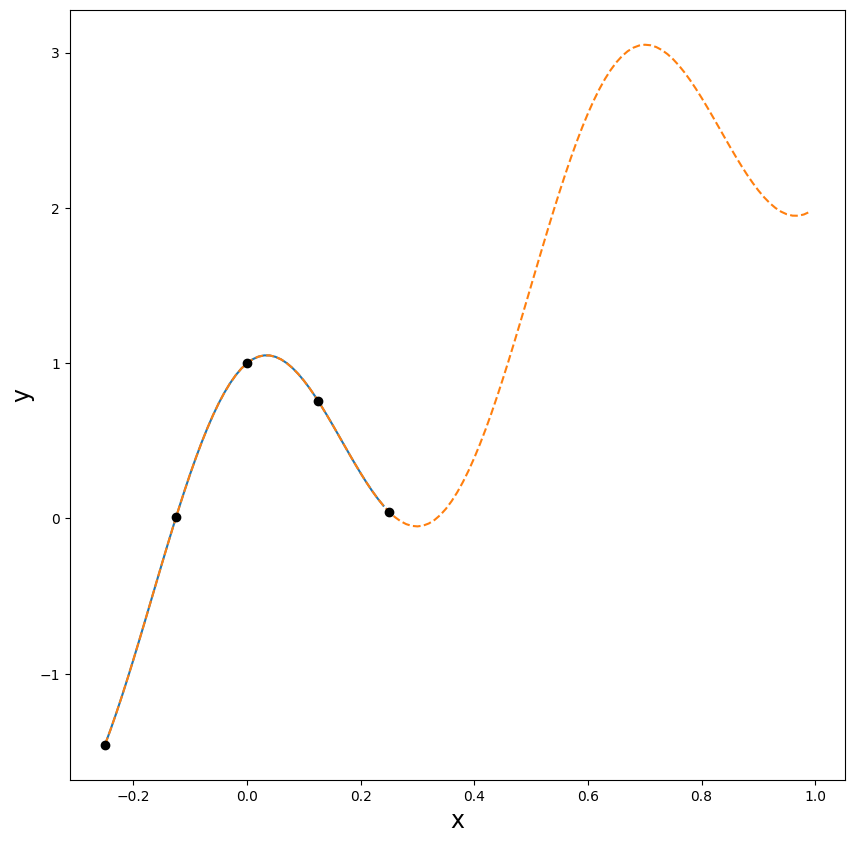

In [244]:
xi = np.arange(-0.25,1,0.01)
xdum = np.arange(-0.25,0.25,0.01)
x = np.array([-0.25,-0.125,0,0.125,0.25])
y = np.cos(-3*np.pi*x) + 3*x
ydum = np.cos(-3*np.pi*xdum) + 3*xdum
yi = np.cos(-3*np.pi*xi) + 3*xi
plt.figure(figsize=(10,10))
plt.plot(xdum,ydum)
plt.plot(xi,yi,'--')
plt.plot(x,y,'o',c='black')
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)

----------------------------------------------------------

## Question 4
## Use bilinear interpolation to determine the value of the function $f(x,y) = z$  at the point $(x_r, y_r)$, given the below four data points $x_i, y_i$ with values $z_{i} = f(x_i,y_i)$


Text(0.17653109507943243, 0.0015530474647270365, '($x_r,y_r)$')

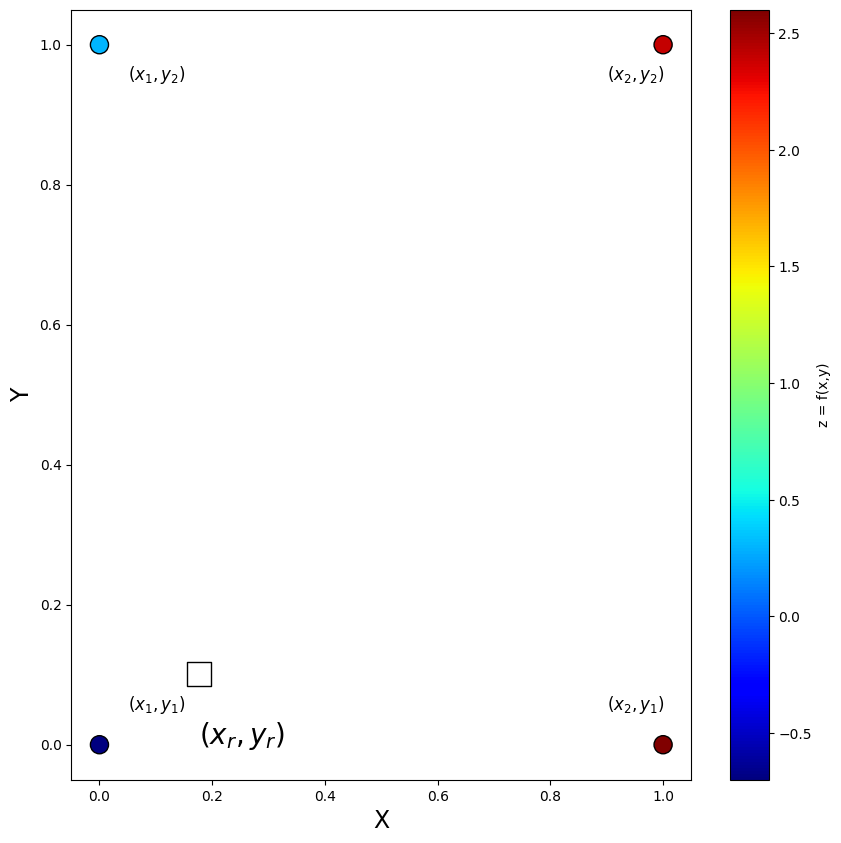

In [245]:
#Known data points and function values.  Listed clockwise from the x_1,y_1 = (0,0) point.
xi = np.array([0,0,1,1])  #x_1,x_1,x_2,x_2
yi = np.array([0,1,1,0])  #y_1,y_2,y_2,y_1
zi = np.array([-0.7,0.3,2.4,2.6])  

#Randomly generate coordinates to find function value (z = f(x,y)) at 
xr = np.random.uniform()
yr = np.random.uniform()

#Visualize
plt.figure(figsize=(10,10))
plt.scatter(xi,yi,c=zi,s=170,marker='o',cmap='jet',edgecolor='black')
plt.colorbar(label='z = f(x,y)')
plt.xlabel('X',fontsize=17)
plt.ylabel('Y',fontsize=17)
plt.scatter(xr,yr,edgecolor='black',marker='s',s=290,c='white')
plt.text(0.05,0.05,'($x_1,y_1)$',fontsize=12)
plt.text(0.05,0.95,'($x_1,y_2)$',fontsize=12)
plt.text(0.9,0.95,'($x_2,y_2)$',fontsize=12)
plt.text(0.9,0.05,'($x_2,y_1)$',fontsize=12)
plt.text(xr,yr-0.1,'($x_r,y_r)$',fontsize=20)





In [246]:
z11 = zi[0] 
z12 = zi[1] 
z22 = zi[2]
z21 = zi[3] 

zr = (z11 * (1 - xr) * (1 - yr) + 
      z12 * (1 - xr) * yr + 
      z22 * xr * yr + 
      z21 * xr * (1 - yr))

print("Interpolated function value:", zr)

Interpolated function value: -0.03740706358626822
